
# CUSTOMER CHURN PREDICTION AND RETENTION ANALYSIS

## Week 6 – Integrated Data Science Project

**Internship:** Data Science Internship

**Project Domain:** Machine Learning and Data Analytics

**Dataset:** Telco Customer Churn Dataset

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

**Environment:** Google Colab

## Project Objective

To analyze customer behavior, identify the factors responsible for customer churn, and develop machine learning models to predict customers who are likely to leave a telecommunications company.


In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Libraries
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Display Settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving EV_Market_Performance_Sample_Dataset.xlsx to EV_Market_Performance_Sample_Dataset.xlsx


In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:

# STEP 5: DATASET UNDERSTANDING

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Display last 5 rows
print("\nLast 5 Rows:")
display(df.tail())

# Dataset information
print("\nDataset Information:")
df.info()

# Dataset shape
print("\nDataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all').T)


First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Last 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

# STEP 6: CHECK MISSING VALUES

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())


Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values:
0

Duplicate Records:
0


In [6]:

# STEP 7: DATA CLEANING

# Convert TotalCharges into numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values after conversion
print("Missing Values After Conversion:")
print(df.isnull().sum())

# Handle missing values
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

# Remove duplicate records if any
df.drop_duplicates(inplace=True)

print("\nData Cleaning Completed Successfully!")

print("Final Dataset Shape:", df.shape)

print("\nMissing Values Remaining:")
print(df.isnull().sum().sum())


Missing Values After Conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Data Cleaning Completed Successfully!
Final Dataset Shape: (7043, 21)

Missing Values Remaining:
0


Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


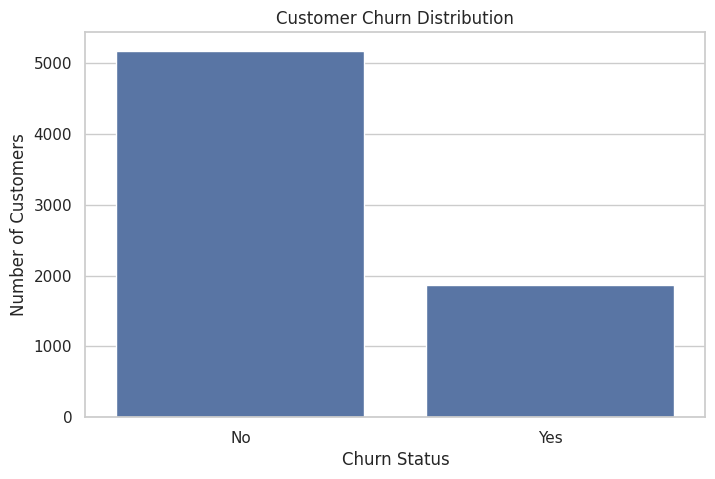

In [7]:

# STEP 8: CHURN DISTRIBUTION

print("Churn Counts:")
print(df['Churn'].value_counts())

print("\nChurn Percentages:")
print(
    (df['Churn'].value_counts(normalize=True) * 100).round(2)
)

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Churn'
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.savefig(
    'churn_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [8]:

# STEP 9: SAVE CLEANED DATASET

df.to_csv(
    'cleaned_customer_churn.csv',
    index=False
)

print("Cleaned Dataset Saved Successfully!")


Cleaned Dataset Saved Successfully!


In [9]:
from google.colab import files

files.download('cleaned_customer_churn.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# EXPLORATORY DATA ANALYSIS (EDA)

Exploratory Data Analysis is performed to understand customer behavior, identify patterns, analyze relationships between variables, and discover factors associated with customer churn.


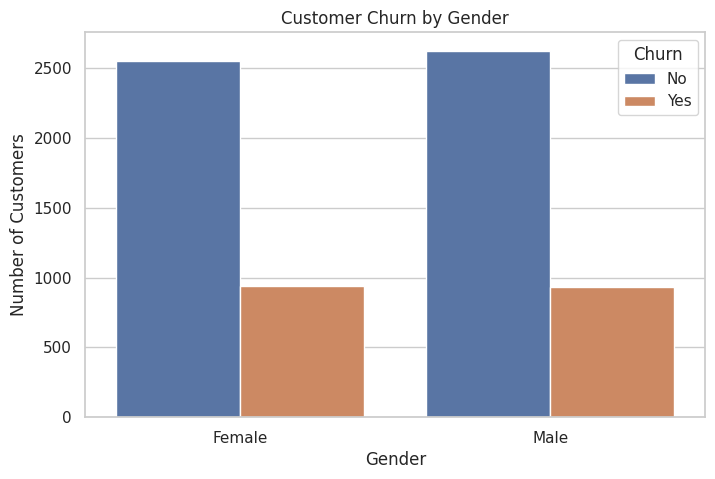

In [10]:

# Gender-wise Churn Analysis

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='gender',
    hue='Churn'
)

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.savefig('gender_churn.png', dpi=300, bbox_inches='tight')
plt.show()


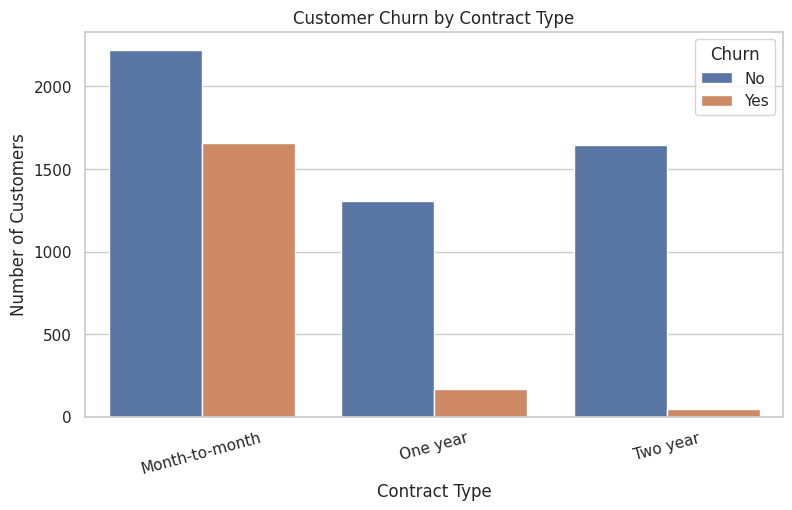

In [11]:

# Contract-wise Churn Analysis

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)
plt.legend(title='Churn')

plt.savefig('contract_churn.png', dpi=300, bbox_inches='tight')
plt.show()


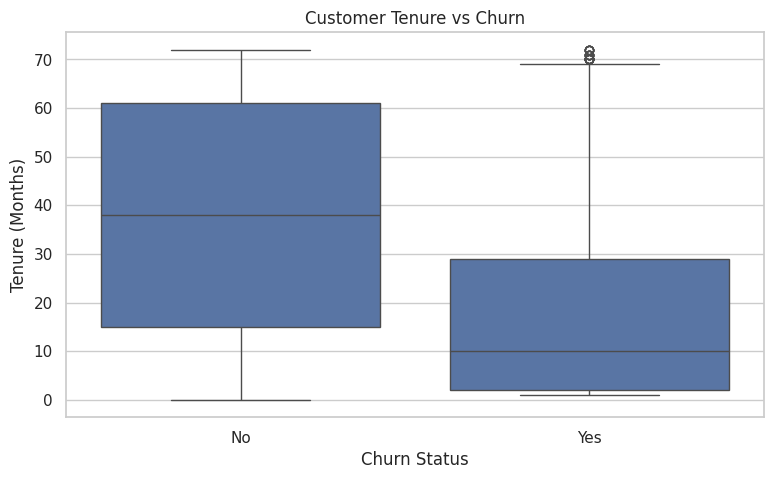

In [12]:

# Tenure Distribution by Churn

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)

plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.savefig('tenure_churn.png', dpi=300, bbox_inches='tight')
plt.show()


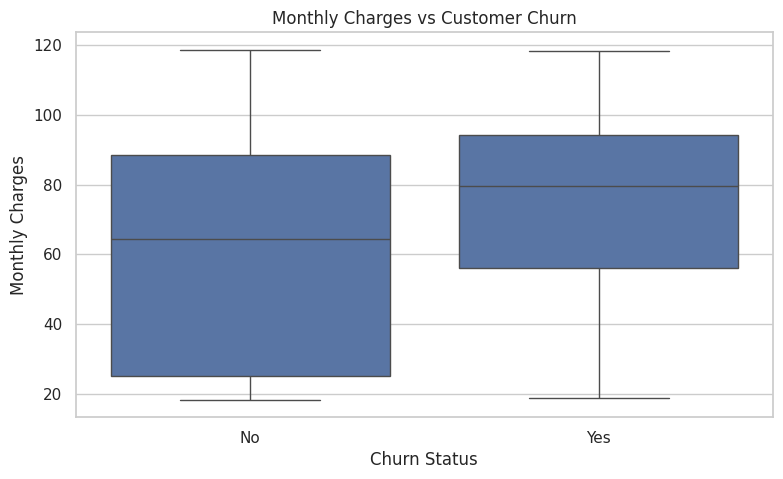

In [13]:

# Monthly Charges Analysis

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.savefig('monthly_charges_churn.png', dpi=300, bbox_inches='tight')
plt.show()


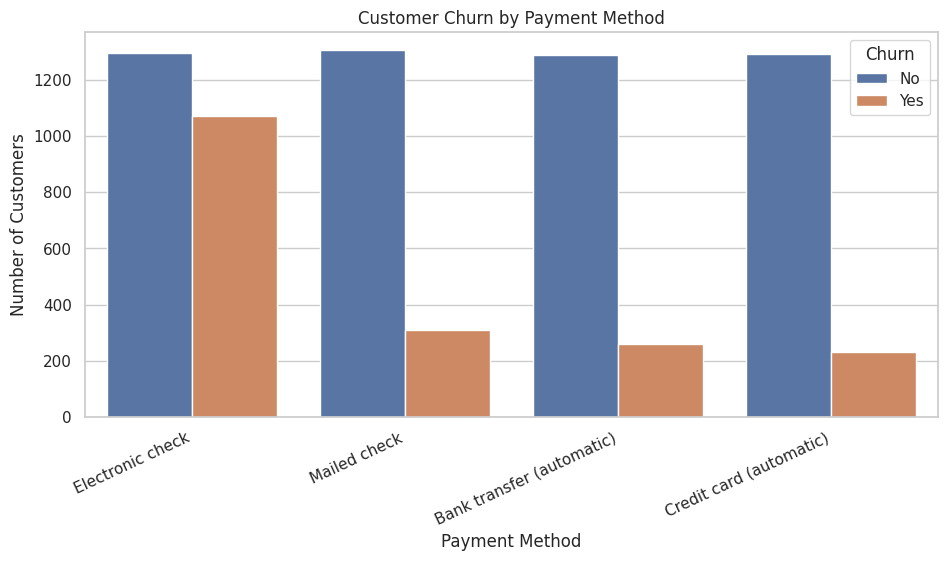

In [14]:

# Payment Method Analysis

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Churn')

plt.savefig('payment_method_churn.png', dpi=300, bbox_inches='tight')
plt.show()


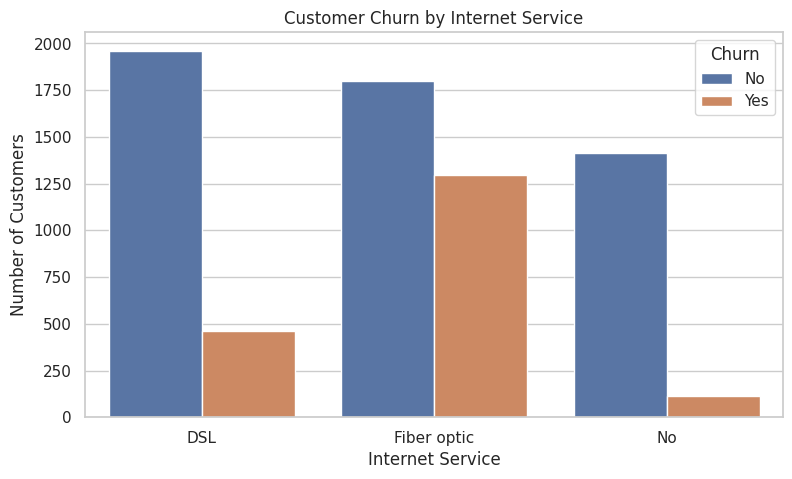

In [15]:

# Internet Service Analysis

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.savefig('internet_service_churn.png', dpi=300, bbox_inches='tight')
plt.show()


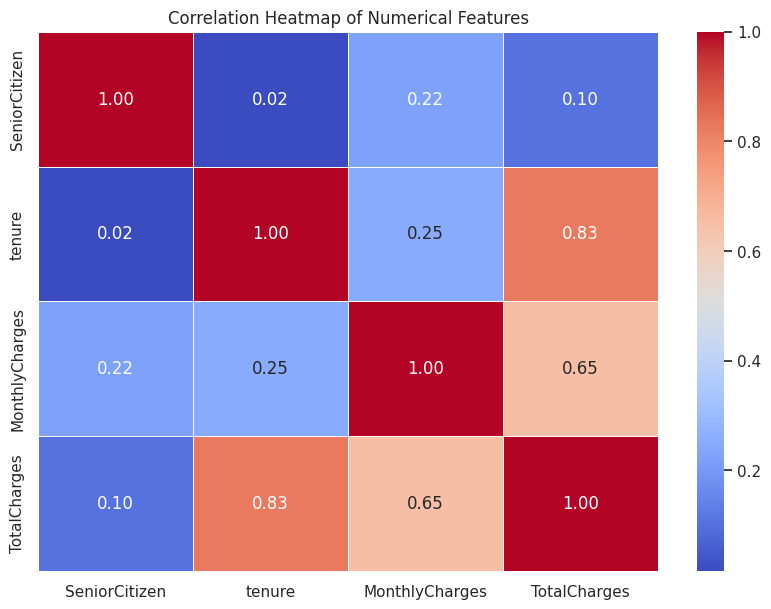

In [16]:

# Correlation Heatmap

numerical_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')

plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


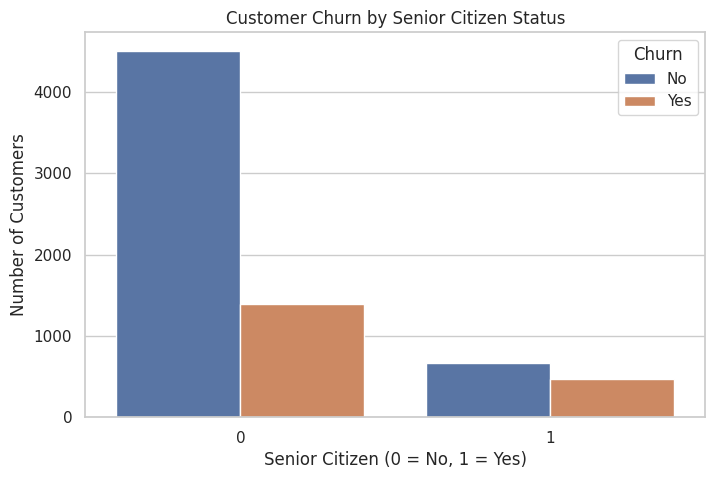

In [17]:

# Senior Citizen Churn Analysis

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='SeniorCitizen',
    hue='Churn'
)

plt.title('Customer Churn by Senior Citizen Status')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.savefig('senior_citizen_churn.png', dpi=300, bbox_inches='tight')
plt.show()


In [18]:

# STATISTICAL ANALYSIS

print("Overall Customer Statistics:")
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe())

print("\nAverage Monthly Charges by Churn:")
display(df.groupby('Churn')['MonthlyCharges'].mean())

print("\nAverage Tenure by Churn:")
display(df.groupby('Churn')['tenure'].mean())

print("\nAverage Total Charges by Churn:")
display(df.groupby('Churn')['TotalCharges'].mean())


Overall Customer Statistics:


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000



Average Monthly Charges by Churn:


,MonthlyCharges
Churn,
No,61.265124
Yes,74.441332



Average Tenure by Churn:


,tenure
Churn,
No,37.569965
Yes,17.979133



Average Total Charges by Churn:


,TotalCharges
Churn,
No,2552.882494
Yes,1531.796094


In [19]:

from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df['Contract'],
    df['Churn']
)

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

if p_value < 0.05:
    print("Result: Significant association exists between Contract and Churn.")
else:
    print("Result: No statistically significant association found.")


Chi-Square Statistic: 1184.5965720837926
P-Value: 5.863038300673391e-258
Degrees of Freedom: 2
Result: Significant association exists between Contract and Churn.



# BUSINESS INSIGHTS

1. Customer tenure helps identify customers who may be at higher risk of leaving.

2. Contract type is an important variable for understanding customer retention.

3. Monthly charges can help identify pricing-related churn patterns.

4. Payment methods may reveal differences in customer churn behavior.

5. Internet service type can provide useful insights into customer satisfaction and retention.

These findings can help businesses design targeted customer retention strategies.


In [20]:

import os
import shutil

os.makedirs('Visualizations', exist_ok=True)

graph_files = [
    'churn_distribution.png',
    'gender_churn.png',
    'contract_churn.png',
    'tenure_churn.png',
    'monthly_charges_churn.png',
    'payment_method_churn.png',
    'internet_service_churn.png',
    'correlation_heatmap.png',
    'senior_citizen_churn.png'
]

for file in graph_files:
    if os.path.exists(file):
        shutil.copy(file, 'Visualizations')

print("All Available Graphs Saved Successfully!")


All Available Graphs Saved Successfully!



# FEATURE ENGINEERING AND DATA PREPROCESSING

Feature engineering involves preparing and transforming raw data into suitable numerical features for machine learning algorithms.


In [21]:

# Remove Customer ID

df = df.drop('customerID', axis=1)

print("Customer ID Column Removed Successfully!")
print("Updated Dataset Shape:", df.shape)


Customer ID Column Removed Successfully!
Updated Dataset Shape: (7043, 20)


In [22]:

# Convert Target Variable into Numerical Format

df['Churn'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

# One-Hot Encoding for Categorical Variables

df_encoded = pd.get_dummies(
    df,
    drop_first=True,
    dtype=int
)

print("Categorical Encoding Completed!")
print("Encoded Dataset Shape:", df_encoded.shape)

display(df_encoded.head())


Categorical Encoding Completed!
Encoded Dataset Shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [23]:

# Separate Independent and Dependent Variables

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (7043, 30)
Target Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [24]:

# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Data Shape: (5634, 30)
Testing Data Shape: (1409, 30)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [25]:

# Apply Standard Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)


Feature Scaling Completed Successfully!
Scaled Training Data Shape: (5634, 30)
Scaled Testing Data Shape: (1409, 30)


In [26]:

# Logistic Regression Model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Model Training Completed!")


Logistic Regression Model Training Completed!


In [27]:

# Decision Tree Model

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Model Training Completed!")


Decision Tree Model Training Completed!


In [28]:

# Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Model Training Completed!")


Random Forest Model Training Completed!


In [29]:

# Model Evaluation Function

def evaluate_model(model_name, actual, predicted, probabilities):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted, zero_division=0),
        'Recall': recall_score(actual, predicted, zero_division=0),
        'F1-Score': f1_score(actual, predicted, zero_division=0),
        'ROC-AUC': roc_auc_score(actual, probabilities)
    }


results = []

results.append(
    evaluate_model('Logistic Regression', y_test, lr_pred, lr_prob)
)

results.append(
    evaluate_model('Decision Tree', y_test, dt_pred, dt_prob)
)

results.append(
    evaluate_model('Random Forest', y_test, rf_pred, rf_prob)
)

comparison_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(comparison_df.round(4))


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8416
1,Decision Tree,0.7942,0.6296,0.5455,0.5845,0.8284
2,Random Forest,0.8041,0.6667,0.5241,0.5868,0.8432


In [30]:

from sklearn.model_selection import GridSearchCV

# Define Parameter Grid

param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs']
}

# Grid Search

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)


Best Parameters: {'C': 10, 'solver': 'liblinear'}
Best Cross-Validation F1 Score: 0.5989694084614318


In [31]:

# Train Best Logistic Regression Model

best_lr_model = grid_search.best_estimator_

tuned_pred = best_lr_model.predict(X_test_scaled)
tuned_prob = best_lr_model.predict_proba(X_test_scaled)[:, 1]

print("Tuned Logistic Regression Training Completed!")


Tuned Logistic Regression Training Completed!


In [32]:

# Final Model Comparison

final_results = []

final_results.append(
    evaluate_model('Logistic Regression', y_test, lr_pred, lr_prob)
)

final_results.append(
    evaluate_model('Decision Tree', y_test, dt_pred, dt_prob)
)

final_results.append(
    evaluate_model('Random Forest', y_test, rf_pred, rf_prob)
)

final_results.append(
    evaluate_model('Tuned Logistic Regression', y_test, tuned_pred, tuned_prob)
)

final_comparison = pd.DataFrame(final_results)

print("Final Model Performance Comparison:")
display(final_comparison.round(4))


Final Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8416
1,Decision Tree,0.7942,0.6296,0.5455,0.5845,0.8284
2,Random Forest,0.8041,0.6667,0.5241,0.5868,0.8432
3,Tuned Logistic Regression,0.8034,0.6520,0.5561,0.6003,0.8410


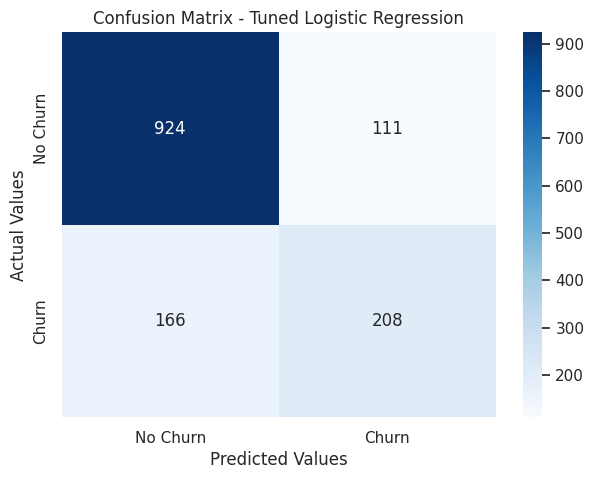

In [33]:

# Confusion Matrix for Final Model

cm = confusion_matrix(y_test, tuned_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Confusion Matrix - Tuned Logistic Regression')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


In [34]:

print("Classification Report:")

print(
    classification_report(
        y_test,
        tuned_pred,
        target_names=['No Churn', 'Churn']
    )
)


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.80      0.80      0.80      1409



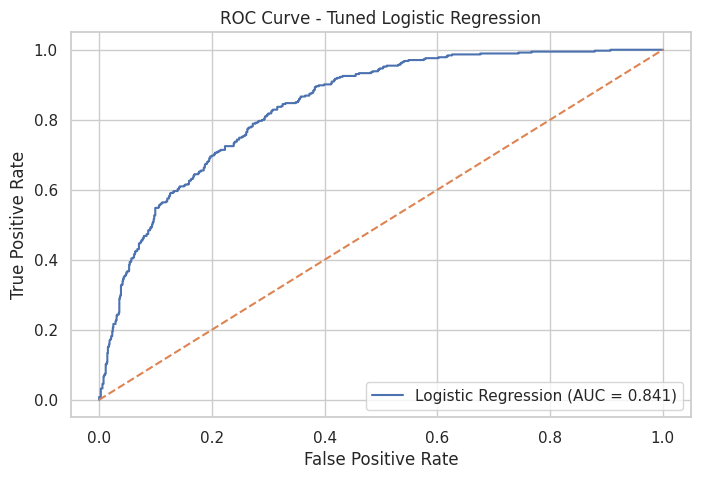

ROC-AUC Score: 0.841


In [35]:

# ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, tuned_prob)

roc_auc = roc_auc_score(y_test, tuned_prob)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('ROC Curve - Tuned Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.savefig('roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))


Top 10 Important Features:


,Feature,Coefficient,Absolute_Importance
2,MonthlyCharges,-2.185580,2.185580
10,InternetService_Fiber optic,1.294388,1.294388
1,tenure,-1.283314,1.283314
25,Contract_Two year,-0.589586,0.589586
3,TotalCharges,0.560404,0.560404
23,StreamingMovies_Yes,0.460869,0.460869
21,StreamingTV_Yes,0.459564,0.459564
9,MultipleLines_Yes,0.319570,0.319570
24,Contract_One year,-0.283890,0.283890
26,PaperlessBilling_Yes,0.181534,0.181534


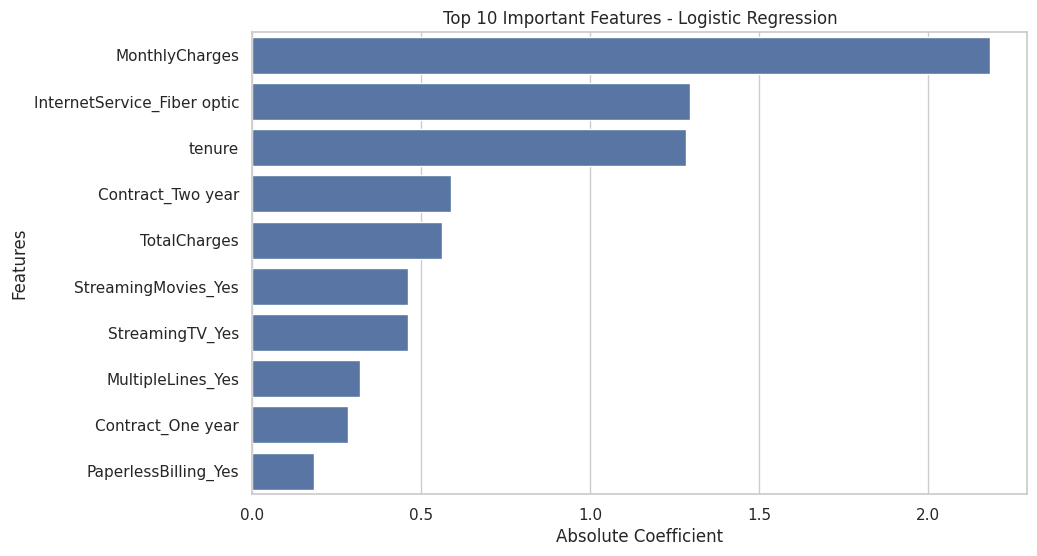

In [36]:

# Feature Importance using Logistic Regression Coefficients

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': best_lr_model.coef_[0]
})

feature_importance['Absolute_Importance'] = (
    feature_importance['Coefficient'].abs()
)

feature_importance = feature_importance.sort_values(
    by='Absolute_Importance',
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Absolute_Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Logistic Regression')
plt.xlabel('Absolute Coefficient')
plt.ylabel('Features')

plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


In [37]:

import joblib
import os

os.makedirs('Models', exist_ok=True)

joblib.dump(best_lr_model, 'Models/best_churn_model.pkl')
joblib.dump(scaler, 'Models/standard_scaler.pkl')

print("Final Model and Scaler Saved Successfully!")


Final Model and Scaler Saved Successfully!



# BUSINESS INSIGHTS AND RECOMMENDATIONS

## Key Business Insights

1. Customer tenure is an important factor in understanding customer retention.

2. Contract type helps identify differences in customer churn behavior.

3. Monthly charges provide useful information about pricing-related customer attrition.

4. Payment methods and internet service types can help identify customer segments with different churn patterns.

5. Machine Learning models can help businesses identify customers who may be at risk of leaving.

## Business Recommendations

1. Introduce loyalty programs for new customers.

2. Offer attractive discounts and long-term subscription plans.

3. Improve customer support and service quality.

4. Identify high-risk customers using the prediction model.

5. Develop personalized retention campaigns for customers likely to churn.

6. Regularly monitor customer satisfaction and service usage.

## Business Impact

The proposed predictive approach can help telecommunications companies make data-driven decisions, identify potential customer attrition, and develop effective customer retention strategies.



# CONCLUSION

The Customer Churn Prediction and Retention Analysis project successfully demonstrates the application of the complete Data Science lifecycle to a real-world business problem.

The project involved data collection, data cleaning, exploratory data analysis, statistical analysis, feature engineering, machine learning model development, and model evaluation.

Multiple classification algorithms, including Logistic Regression, Decision Tree, and Random Forest, were implemented and compared. Hyperparameter tuning was also performed to improve predictive performance.

The final model was selected by considering multiple evaluation metrics, particularly recall and F1-score, to identify customers who are likely to leave the company.

The analysis provides useful insights into customer behavior and highlights how predictive analytics can support customer retention strategies.

Overall, this project demonstrates how Python and Machine Learning can be used to solve practical business problems and support data-driven decision-making.



# LIMITATIONS

1. The project uses a publicly available dataset that may not represent every telecommunications company.

2. Customer behavior may change over time, affecting model performance.

3. The prediction model depends on the quality and availability of input data.

4. The analysis does not include all possible external factors affecting customer decisions.

# FUTURE SCOPE

1. Deploy the final model as a web application using Flask or Streamlit.

2. Use larger and more recent customer datasets.

3. Explore advanced algorithms such as XGBoost and Gradient Boosting.

4. Apply SHAP to improve model explainability.

5. Develop a real-time customer churn monitoring dashboard.

6. Integrate the model with business customer relationship management systems.


In [38]:

import os
import shutil

# Create final project folders
folders = [
    'Final_Project/Dataset',
    'Final_Project/Notebooks',
    'Final_Project/Visualizations',
    'Final_Project/Models',
    'Final_Project/Reports'
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Save cleaned dataset
df.to_csv(
    'Final_Project/Dataset/cleaned_customer_churn.csv',
    index=False
)

# Save notebook-compatible model results
final_comparison.to_csv(
    'Final_Project/model_comparison.csv',
    index=False
)

# Copy available visualization files
for file in os.listdir('.'):
    if file.endswith('.png'):
        shutil.copy(
            file,
            'Final_Project/Visualizations/'
        )

print("Supporting Files Organized Successfully!")


Supporting Files Organized Successfully!



# ADVANCED MODEL VALIDATION
## 5-Fold Stratified Cross Validation

Cross-validation is used to evaluate model performance across multiple data splits and assess the consistency and reliability of the machine learning model.


In [40]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# Create a Machine Learning Pipeline
cv_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        C=best_lr_model.C,
        solver=best_lr_model.solver,
        max_iter=1000,
        random_state=42
    ))
])

# Define 5-Fold Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation Metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Perform Cross Validation
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display Results
print("5-Fold Cross Validation Results")

for metric in scoring:
    scores = cv_results['test_' + metric]

    print(
        f"{metric.upper()}: "
        f"Mean = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )


5-Fold Cross Validation Results
ACCURACY: Mean = 0.8037, Std = 0.0124
PRECISION: Mean = 0.6554, Std = 0.0276
RECALL: Mean = 0.5492, Std = 0.0385
F1: Mean = 0.5971, Std = 0.0295
ROC_AUC: Mean = 0.8463, Std = 0.0128


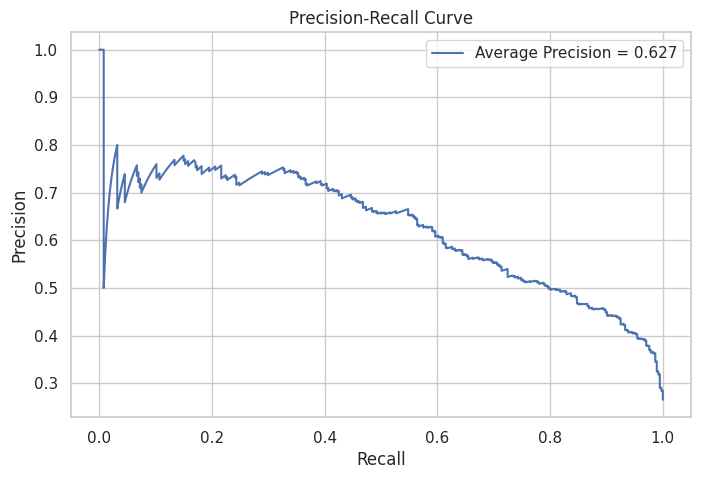

Average Precision Score: 0.6273


In [41]:

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

# Calculate Precision and Recall
precision, recall, thresholds = precision_recall_curve(
    y_test,
    tuned_prob
)

# Calculate Average Precision
avg_precision = average_precision_score(
    y_test,
    tuned_prob
)

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f'Average Precision = {avg_precision:.3f}'
)

plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()

plt.savefig(
    'precision_recall_curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Average Precision Score:", round(avg_precision, 4))


In [42]:

# Customer Risk Segmentation

risk_data = X_test.copy()

risk_data['Actual_Churn'] = y_test.values
risk_data['Churn_Probability'] = tuned_prob

def assign_risk(probability):

    if probability >= 0.70:
        return 'High Risk'

    elif probability >= 0.40:
        return 'Medium Risk'

    else:
        return 'Low Risk'

risk_data['Risk_Category'] = (
    risk_data['Churn_Probability'].apply(assign_risk)
)

print("Customer Risk Segmentation:")
display(risk_data[
    ['Actual_Churn', 'Churn_Probability', 'Risk_Category']
].head(15))

print("\nRisk Category Distribution:")
print(risk_data['Risk_Category'].value_counts())


Customer Risk Segmentation:


,Actual_Churn,Churn_Probability,Risk_Category
437,0,0.047581,Low Risk
2280,0,0.682532,Medium Risk
2235,0,0.048982,Low Risk
4460,0,0.425630,Medium Risk
3761,0,0.023219,Low Risk
5748,0,0.603833,Medium Risk
3568,0,0.458207,Medium Risk
2976,0,0.133930,Low Risk
5928,0,0.002659,Low Risk
1639,1,0.392896,Low Risk



Risk Category Distribution:
Risk_Category
Low Risk       969
Medium Risk    349
High Risk       91
Name: count, dtype: int64


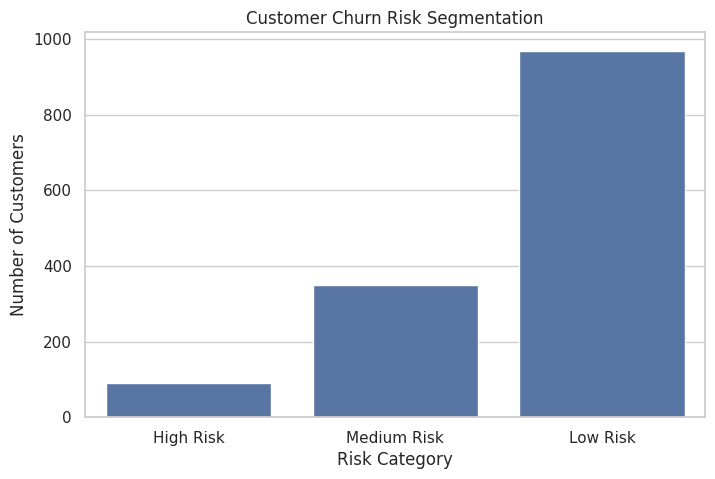

In [43]:

# Visualize Customer Risk Categories

plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_data,
    x='Risk_Category',
    order=['High Risk', 'Medium Risk', 'Low Risk']
)

plt.title('Customer Churn Risk Segmentation')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')

plt.savefig(
    'customer_risk_segmentation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


Top 10 Features Based on Permutation Importance:


,Feature,Importance
1,tenure,0.231217
10,InternetService_Fiber optic,0.175487
2,MonthlyCharges,0.109370
25,Contract_Two year,0.085290
23,StreamingMovies_Yes,0.050916
21,StreamingTV_Yes,0.042227
9,MultipleLines_Yes,0.029333
24,Contract_One year,0.028646
28,PaymentMethod_Electronic check,0.021662
26,PaperlessBilling_Yes,0.019419


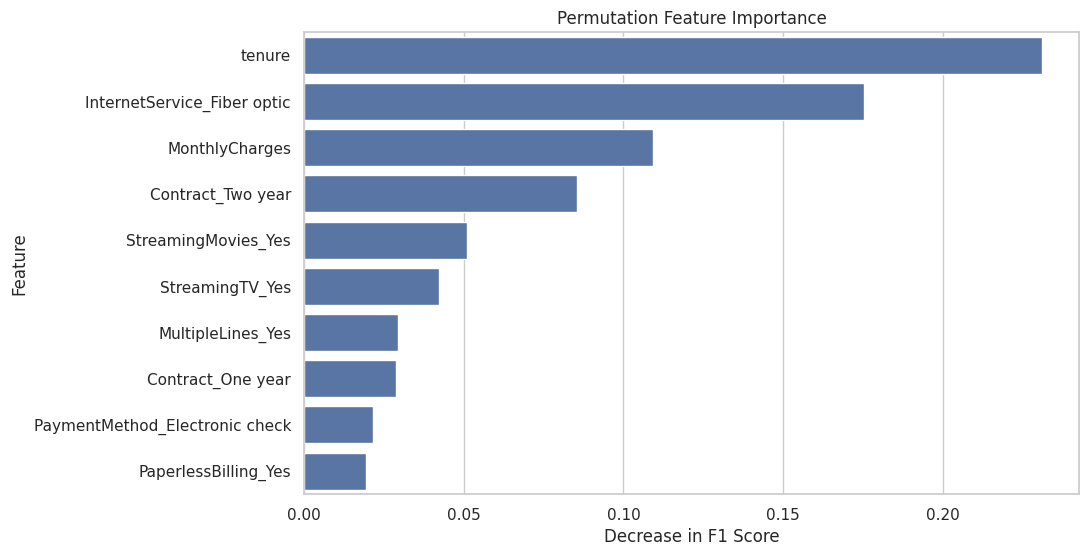

In [44]:

from sklearn.inspection import permutation_importance

# Calculate Permutation Importance
perm_result = permutation_importance(
    best_lr_model,
    X_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1'
)

# Create Importance DataFrame
perm_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_result.importances_mean
})

perm_importance = perm_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Features Based on Permutation Importance:")
display(perm_importance.head(10))

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=perm_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Permutation Feature Importance')
plt.xlabel('Decrease in F1 Score')
plt.ylabel('Feature')

plt.savefig(
    'permutation_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [45]:
!pip install shap

In [46]:

import shap

# Create SHAP Explainer
explainer = shap.LinearExplainer(
    best_lr_model,
    X_train_scaled
)

# Calculate SHAP Values
shap_values = explainer(
    X_test_scaled[:200]
)

print("SHAP Analysis Completed Successfully!")


SHAP Analysis Completed Successfully!


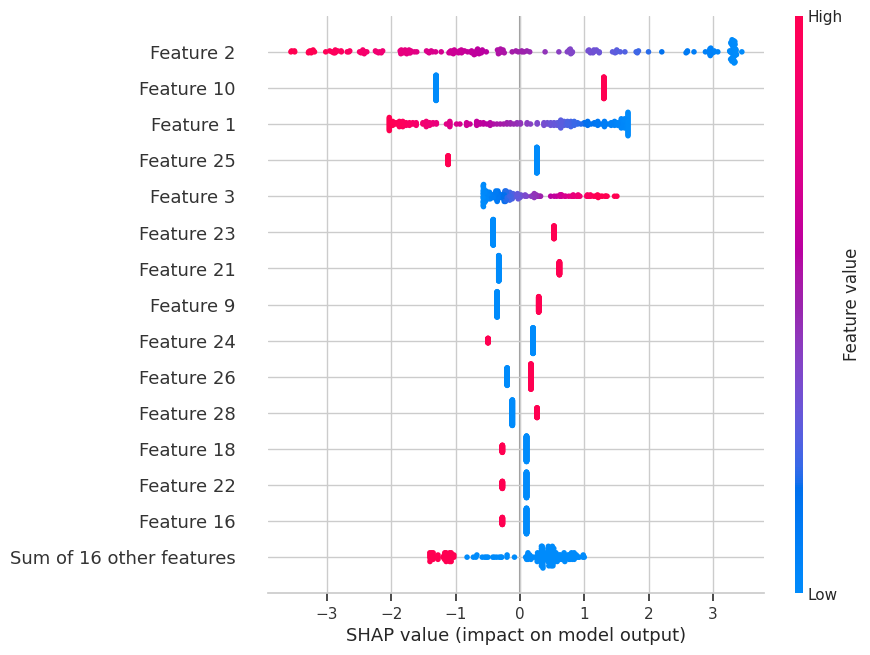

In [47]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

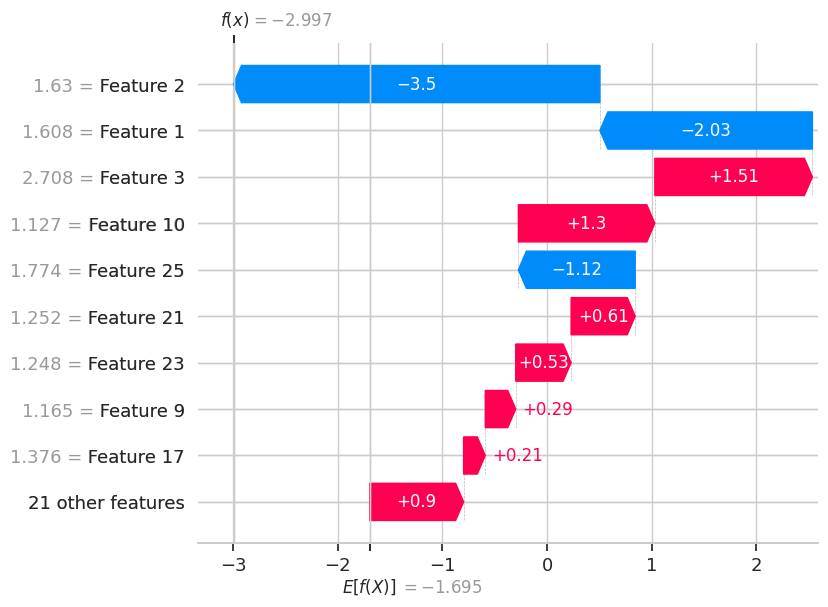

In [48]:
shap.plots.waterfall(
    shap_values[0],
    max_display=10
)

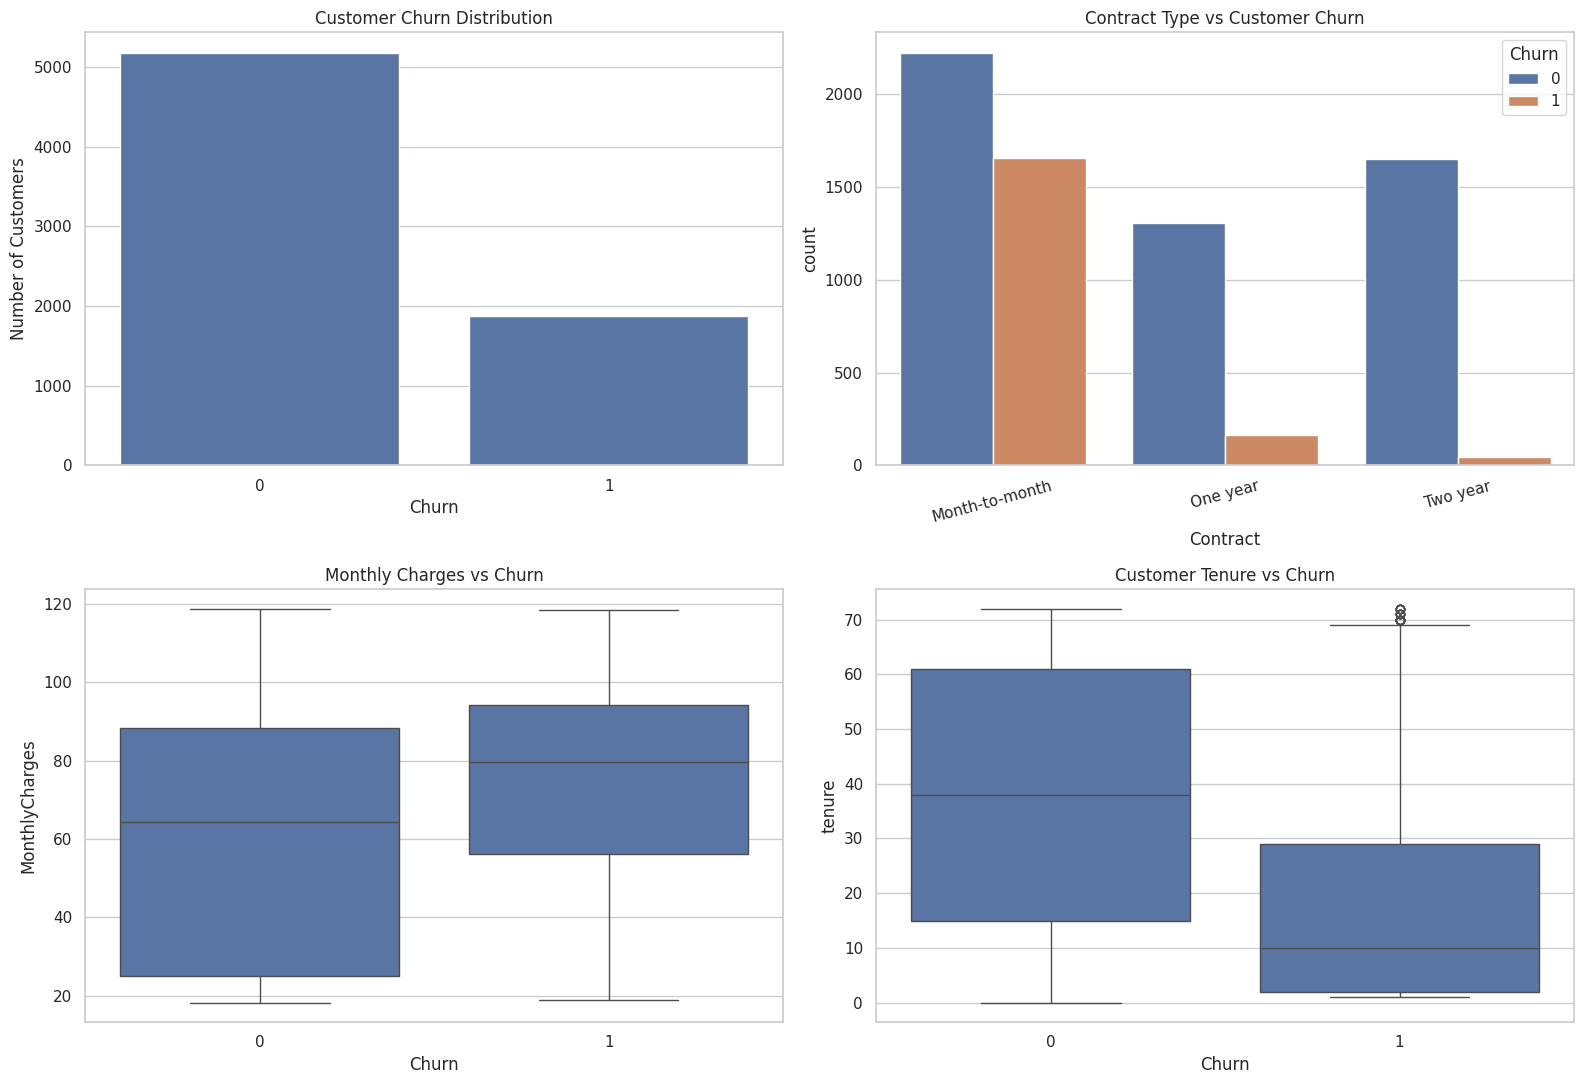

Customer Churn Insights Dashboard Created Successfully!


In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create dashboard with multiple charts
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual Churn Distribution
sns.countplot(data=df, x='Churn', ax=axes[0, 0])
axes[0, 0].set_title('Customer Churn Distribution')
axes[0, 0].set_xlabel('Churn')
axes[0, 0].set_ylabel('Number of Customers')

# 2. Contract Type vs Churn
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0, 1])
axes[0, 1].set_title('Contract Type vs Customer Churn')
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Monthly Charges by Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1, 0])
axes[1, 0].set_title('Monthly Charges vs Churn')

# 4. Tenure by Churn
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[1, 1])
axes[1, 1].set_title('Customer Tenure vs Churn')

plt.tight_layout()
plt.savefig('customer_churn_insights_dashboard.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("Customer Churn Insights Dashboard Created Successfully!")

Customer Risk Analysis:


,Risk_Category,Customer_Count,Average_Churn_Probability,Actual_Churn_Rate
0,High Risk,91,0.751690,74.725275
1,Low Risk,969,0.120889,13.003096
2,Medium Risk,349,0.550325,51.575931


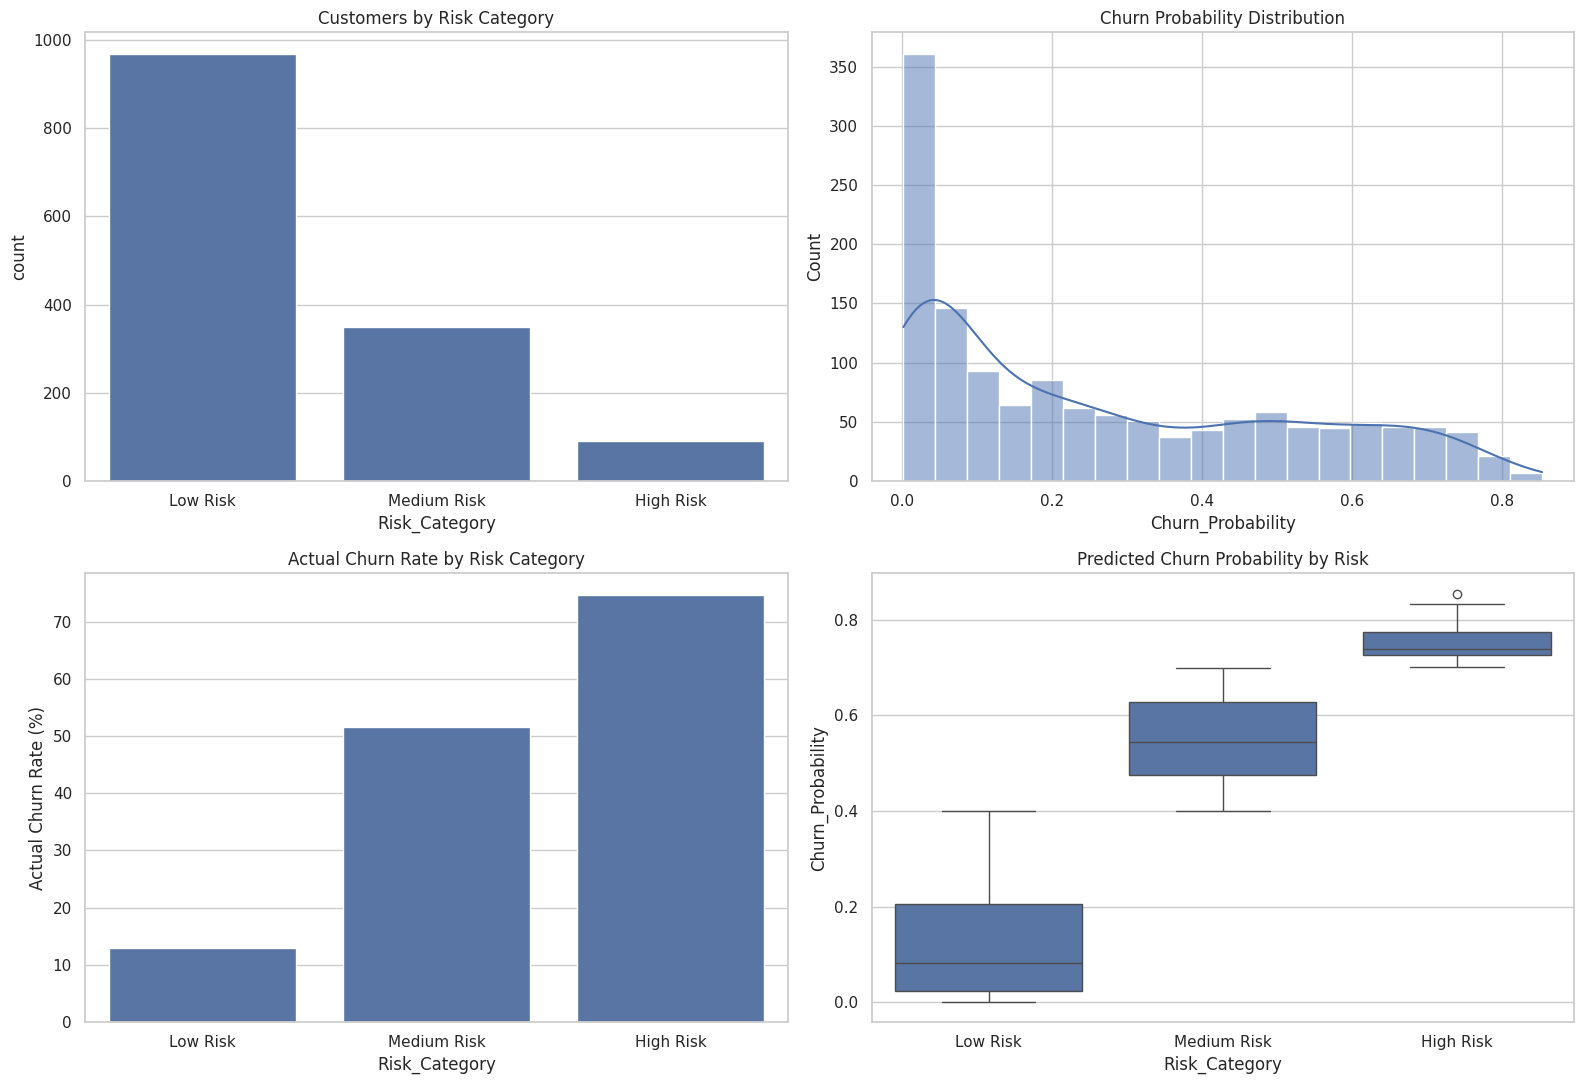

Customer Risk Analysis Dashboard Created Successfully!


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Risk category summary
risk_summary = risk_data.groupby('Risk_Category').agg(
    Customer_Count=('Churn_Probability', 'count'),
    Average_Churn_Probability=('Churn_Probability', 'mean'),
    Actual_Churn_Rate=('Actual_Churn', 'mean')
).reset_index()

risk_summary['Actual_Churn_Rate'] *= 100

print("Customer Risk Analysis:")
display(risk_summary)

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Number of customers in each risk category
sns.countplot(
    data=risk_data,
    x='Risk_Category',
    order=['Low Risk', 'Medium Risk', 'High Risk'],
    ax=axes[0, 0]
)
axes[0, 0].set_title('Customers by Risk Category')

# 2. Churn probability distribution
sns.histplot(
    data=risk_data,
    x='Churn_Probability',
    bins=20,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Churn Probability Distribution')

# 3. Actual churn rate by risk category
sns.barplot(
    data=risk_summary,
    x='Risk_Category',
    y='Actual_Churn_Rate',
    order=['Low Risk', 'Medium Risk', 'High Risk'],
    ax=axes[1, 0]
)
axes[1, 0].set_title('Actual Churn Rate by Risk Category')
axes[1, 0].set_ylabel('Actual Churn Rate (%)')

# 4. Predicted churn probability by risk category
sns.boxplot(
    data=risk_data,
    x='Risk_Category',
    y='Churn_Probability',
    order=['Low Risk', 'Medium Risk', 'High Risk'],
    ax=axes[1, 1]
)
axes[1, 1].set_title('Predicted Churn Probability by Risk')

plt.tight_layout()
plt.savefig(
    'customer_risk_analysis_dashboard.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print("Customer Risk Analysis Dashboard Created Successfully!")

In [51]:
import joblib
import os

# Create model folder
os.makedirs("Models", exist_ok=True)

# Save trained model
joblib.dump(best_lr_model, "Models/churn_model.pkl")

# Save scaler
joblib.dump(scaler, "Models/scaler.pkl")

# Save feature columns
joblib.dump(X.columns.tolist(), "Models/feature_columns.pkl")

# Save TotalCharges median for missing-value handling
joblib.dump(df['TotalCharges'].median(), "Models/totalcharges_median.pkl")

print("All Model Files Saved Successfully!")

print("\nSaved Files:")
print(os.listdir("Models"))

All Model Files Saved Successfully!

Saved Files:
['totalcharges_median.pkl', 'standard_scaler.pkl', 'scaler.pkl', 'feature_columns.pkl', 'churn_model.pkl', 'best_churn_model.pkl']


In [52]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

# Load saved files
model = joblib.load("Models/churn_model.pkl")
scaler = joblib.load("Models/scaler.pkl")
feature_columns = joblib.load("Models/feature_columns.pkl")
totalcharges_median = joblib.load("Models/totalcharges_median.pkl")

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Prediction System")
st.write("Predict customer churn risk using Machine Learning.")

st.subheader("Enter Customer Information")

with st.form("customer_form"):

    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Male", "Female"])
        senior = st.selectbox("Senior Citizen", [0, 1])
        partner = st.selectbox("Partner", ["Yes", "No"])
        dependents = st.selectbox("Dependents", ["Yes", "No"])
        tenure = st.number_input("Tenure (Months)", 0, 72, 12)
        phone = st.selectbox("Phone Service", ["Yes", "No"])
        multiple_lines = st.selectbox(
            "Multiple Lines", ["No", "Yes", "No phone service"]
        )
        internet = st.selectbox(
            "Internet Service", ["DSL", "Fiber optic", "No"]
        )
        online_security = st.selectbox(
            "Online Security", ["Yes", "No", "No internet service"]
        )
        online_backup = st.selectbox(
            "Online Backup", ["Yes", "No", "No internet service"]
        )

    with col2:
        device_protection = st.selectbox(
            "Device Protection", ["Yes", "No", "No internet service"]
        )
        tech_support = st.selectbox(
            "Tech Support", ["Yes", "No", "No internet service"]
        )
        streaming_tv = st.selectbox(
            "Streaming TV", ["Yes", "No", "No internet service"]
        )
        streaming_movies = st.selectbox(
            "Streaming Movies", ["Yes", "No", "No internet service"]
        )
        contract = st.selectbox(
            "Contract", ["Month-to-month", "One year", "Two year"]
        )
        paperless = st.selectbox("Paperless Billing", ["Yes", "No"])
        payment = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )
        monthly = st.number_input("Monthly Charges", 0.0, 200.0, 70.0)
        total = st.number_input("Total Charges", 0.0, 10000.0, 840.0)

    submitted = st.form_submit_button("Predict Customer Churn")

if submitted:

    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": multiple_lines,
        "InternetService": internet,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly,
        "TotalCharges": total
    }])

    customer["TotalCharges"] = pd.to_numeric(
        customer["TotalCharges"], errors="coerce"
    ).fillna(totalcharges_median)

    encoded = pd.get_dummies(customer, drop_first=True, dtype=int)
    encoded = encoded.reindex(columns=feature_columns, fill_value=0)

    scaled = scaler.transform(encoded)

    probability = model.predict_proba(scaled)[0][1]
    prediction = model.predict(scaled)[0]

    st.subheader("Prediction Result")
    st.metric("Churn Probability", f"{probability * 100:.2f}%")

    if probability >= 0.70:
        st.error("High Risk: Customer is likely to churn.")
        st.write("Recommendation: Contact the customer and offer a suitable retention plan.")

    elif probability >= 0.40:
        st.warning("Medium Risk: Customer needs attention.")
        st.write("Recommendation: Improve customer engagement and monitor satisfaction.")

    else:
        st.success("Low Risk: Customer is less likely to churn.")
        st.write("Recommendation: Maintain service quality and customer relationship.")

    st.write(
        "Model Prediction:",
        "Churn" if prediction == 1 else "No Churn"
    )

Writing app.py


In [61]:
!pip install streamlit

In [62]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
added 22 packages in 5s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇

In [63]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [64]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://yummy-hornets-sink.loca.lt
^C


In [65]:
!wget -q -O - ipv4.icanhazip.com

34.181.163.11


In [66]:
import os

folders = [
    "Final_Project/Dataset",
    "Final_Project/Notebooks",
    "Final_Project/Visualizations",
    "Final_Project/Models",
    "Final_Project/Reports",
    "Final_Project/Documentation",
    "Final_Project/App"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Professional Project Folder Structure Created!")

Professional Project Folder Structure Created!


In [67]:
import os
import shutil

# 1. Save cleaned dataset
df.to_csv(
    "Final_Project/Dataset/cleaned_customer_churn.csv",
    index=False
)

# 2. Save processed dataset
df_encoded.to_csv(
    "Final_Project/Dataset/encoded_customer_churn.csv",
    index=False
)

# 3. Copy trained model files
for file in [
    "churn_model.pkl",
    "scaler.pkl",
    "feature_columns.pkl",
    "totalcharges_median.pkl"
]:
    source = "Models/" + file
    destination = "Final_Project/Models/" + file

    if os.path.exists(source):
        shutil.copy(source, destination)
        print("Copied:", file)
    else:
        print("File not found:", source)

print("\nDataset and Model Files Organized Successfully!")

Copied: churn_model.pkl
Copied: scaler.pkl
Copied: feature_columns.pkl
Copied: totalcharges_median.pkl

Dataset and Model Files Organized Successfully!


In [68]:
for root, dirs, files in os.walk("Final_Project"):
    print("\nFolder:", root)

    for file in files:
        print("  -", file)


Folder: Final_Project
  - model_comparison.csv

Folder: Final_Project/App

Folder: Final_Project/Models
  - totalcharges_median.pkl
  - scaler.pkl
  - feature_columns.pkl
  - churn_model.pkl

Folder: Final_Project/Dataset
  - encoded_customer_churn.csv
  - cleaned_customer_churn.csv

Folder: Final_Project/Reports

Folder: Final_Project/Visualizations
  - confusion_matrix.png
  - churn_distribution.png
  - monthly_charges_churn.png
  - contract_churn.png
  - payment_method_churn.png
  - tenure_churn.png
  - senior_citizen_churn.png
  - gender_churn.png
  - feature_importance.png
  - roc_curve.png
  - correlation_heatmap.png
  - internet_service_churn.png

Folder: Final_Project/Documentation

Folder: Final_Project/Notebooks


In [69]:
import os
import shutil

# Copy app.py
if os.path.exists("app.py"):
    shutil.copy(
        "app.py",
        "Final_Project/App/app.py"
    )
    print("Streamlit App Copied Successfully!")

# Copy additional visualization images
image_files = [
    "customer_churn_insights_dashboard.png",
    "customer_risk_analysis_dashboard.png",
    "permutation_feature_importance.png",
    "shap_beeswarm.png",
    "shap_waterfall.png",
    "precision_recall_curve.png"
]

for file in image_files:
    if os.path.exists(file):
        shutil.copy(
            file,
            "Final_Project/Visualizations/" + file
        )
        print("Copied:", file)
    else:
        print("Not found yet:", file)

Streamlit App Copied Successfully!
Copied: customer_churn_insights_dashboard.png
Copied: customer_risk_analysis_dashboard.png
Not found yet: permutation_feature_importance.png
Not found yet: shap_beeswarm.png
Not found yet: shap_waterfall.png
Copied: precision_recall_curve.png


In [70]:
for root, dirs, files in os.walk("Final_Project"):
    print("\n📁", root)
    for file in files:
        print("   📄", file)


📁 Final_Project
   📄 model_comparison.csv

📁 Final_Project/App
   📄 app.py

📁 Final_Project/Models
   📄 totalcharges_median.pkl
   📄 scaler.pkl
   📄 feature_columns.pkl
   📄 churn_model.pkl

📁 Final_Project/Dataset
   📄 encoded_customer_churn.csv
   📄 cleaned_customer_churn.csv

📁 Final_Project/Reports

📁 Final_Project/Visualizations
   📄 confusion_matrix.png
   📄 churn_distribution.png
   📄 monthly_charges_churn.png
   📄 contract_churn.png
   📄 customer_risk_analysis_dashboard.png
   📄 customer_churn_insights_dashboard.png
   📄 precision_recall_curve.png
   📄 payment_method_churn.png
   📄 tenure_churn.png
   📄 senior_citizen_churn.png
   📄 gender_churn.png
   📄 feature_importance.png
   📄 roc_curve.png
   📄 correlation_heatmap.png
   📄 internet_service_churn.png

📁 Final_Project/Documentation

📁 Final_Project/Notebooks


In [71]:
import os
import matplotlib.pyplot as plt
import shap

# Create SHAP Beeswarm plot
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.savefig(
    "Final_Project/Visualizations/shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Create SHAP Waterfall plot
shap.plots.waterfall(
    shap_values[0],
    max_display=10,
    show=False
)

plt.savefig(
    "Final_Project/Visualizations/shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("SHAP Visualizations Saved Successfully!")

SHAP Visualizations Saved Successfully!


In [72]:

import shutil
from google.colab import files

shutil.make_archive(
    'Customer_Churn_Final_Project',
    'zip',
    'Final_Project'
)

files.download('Customer_Churn_Final_Project.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
readme_content = """
# Customer Churn Prediction and Retention Analysis

## Project Overview
This project uses Machine Learning to predict customer churn
and identify customers who may leave a telecom service.

The goal is to help businesses understand customer behaviour,
identify churn risks, and develop customer retention strategies.

## Objectives
- Analyze customer churn patterns.
- Perform data cleaning and preprocessing.
- Explore customer behaviour through visualizations.
- Train and compare Machine Learning models.
- Evaluate model performance using classification metrics.
- Explain model predictions using SHAP.
- Segment customers into Low, Medium, and High Risk categories.
- Develop an interactive Streamlit application.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- SHAP
- Streamlit
- Joblib
- Google Colab

## Machine Learning Models
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- Hyperparameter-tuned Logistic Regression

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix
- Cross-validation

## Project Structure

```text
Final_Project/
|
|-- Dataset/
|   |-- cleaned_customer_churn.csv
|   |-- encoded_customer_churn.csv
|
|-- Models/
|   |-- churn_model.pkl
|   |-- scaler.pkl
|   |-- feature_columns.pkl
|   |-- totalcharges_median.pkl
|
|-- Visualizations/
|   |-- EDA charts
|   |-- Model evaluation charts
|   |-- Customer risk dashboards
|   |-- SHAP visualizations
|
|-- App/
|   |-- app.py
|
|-- Notebooks/
|   |-- Customer_Churn_Prediction_Week6.ipynb
|
|-- Reports/
|-- Documentation/
|-- model_comparison.csv
|-- README.md
|-- requirements.txt

## Conclusion
This project demonstrates an end-to-end Machine Learning
workflow for customer churn prediction, model evaluation,
explainability, and customer retention insights.

## Author
Ankita Sahu
B.Tech Student | Data Science Intern
"""

with open("Final_Project/README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("Professional README.md Created Successfully!")

Professional README.md Created Successfully!


In [75]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
streamlit
joblib
shap
"""

with open("Final_Project/requirements.txt", "w") as f:
    f.write(requirements.strip())

print("requirements.txt Created Successfully!")

requirements.txt Created Successfully!


In [76]:
import pandas as pd
import os

# Load final model comparison
comparison = pd.read_csv("Final_Project/model_comparison.csv")

print("FINAL MODEL PERFORMANCE COMPARISON")
display(comparison)

# Save a report copy
comparison.to_csv(
    "Final_Project/Reports/final_model_performance.csv",
    index=False
)

print("Model Performance Report Data Saved Successfully!")

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.806955,0.658385,0.566845,0.609195,0.841585
1,Decision Tree,0.794180,0.629630,0.545455,0.584527,0.828358
2,Random Forest,0.804116,0.666667,0.524064,0.586826,0.843226
3,Tuned Logistic Regression,0.803407,0.652038,0.556150,0.600289,0.840954


Model Performance Report Data Saved Successfully!


In [77]:
import os

print("FINAL PROJECT FILE CHECK\n")

for folder, dirs, files in os.walk("Final_Project"):
    print(f"\n{folder}")

    for file in files:
        print("  ", file)

print("\nTotal Project Files:",
      sum(len(files) for _, _, files in os.walk("Final_Project")))

FINAL PROJECT FILE CHECK


Final_Project
   README.md
   model_comparison.csv
   requirements.txt

Final_Project/App
   app.py

Final_Project/Models
   totalcharges_median.pkl
   scaler.pkl
   feature_columns.pkl
   churn_model.pkl

Final_Project/Dataset
   encoded_customer_churn.csv
   cleaned_customer_churn.csv

Final_Project/Reports
   final_model_performance.csv

Final_Project/Visualizations
   confusion_matrix.png
   churn_distribution.png
   monthly_charges_churn.png
   contract_churn.png
   customer_risk_analysis_dashboard.png
   customer_churn_insights_dashboard.png
   shap_beeswarm.png
   precision_recall_curve.png
   shap_waterfall.png
   payment_method_churn.png
   tenure_churn.png
   senior_citizen_churn.png
   gender_churn.png
   feature_importance.png
   roc_curve.png
   correlation_heatmap.png
   internet_service_churn.png

Final_Project/Documentation

Final_Project/Notebooks

Total Project Files: 28


In [78]:
import pandas as pd

comparison = pd.read_csv(
    "Final_Project/Reports/final_model_performance.csv"
)

print("FINAL MACHINE LEARNING MODEL COMPARISON")
display(comparison)

FINAL MACHINE LEARNING MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.806955,0.658385,0.566845,0.609195,0.841585
1,Decision Tree,0.794180,0.629630,0.545455,0.584527,0.828358
2,Random Forest,0.804116,0.666667,0.524064,0.586826,0.843226
3,Tuned Logistic Regression,0.803407,0.652038,0.556150,0.600289,0.840954


In [79]:
!pip install python-docx

In [80]:
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
import pandas as pd
import os

# Create Word document
doc = Document()

# Page margins
for section in doc.sections:
    section.top_margin = Inches(0.7)
    section.bottom_margin = Inches(0.7)
    section.left_margin = Inches(0.8)
    section.right_margin = Inches(0.8)

# Default font
styles = doc.styles
styles['Normal'].font.name = 'Arial'
styles['Normal'].font.size = Pt(10)

# Title page
title = doc.add_heading(
    'CUSTOMER CHURN PREDICTION',
    0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

subtitle = doc.add_paragraph(
    'AND RETENTION ANALYSIS'
)
subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_paragraph('\n')

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
run = p.add_run(
    'A Machine Learning Based Data Science Project'
)
run.bold = True
run.font.size = Pt(15)

doc.add_paragraph('\n\n')

for line in [
    'Submitted By: Ankita Sahu',
    'Course: B.Tech',
    'Internship: Data Science Internship',
    'Project: Week 6 – Integrated Project and Comprehensive Reporting'
]:
    p = doc.add_paragraph(line)
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_page_break()

# 1. Executive Summary
doc.add_heading('1. Executive Summary', level=1)

doc.add_paragraph(
    'Customer churn refers to customers discontinuing their '
    'services with a company. This project develops a Machine '
    'Learning based customer churn prediction system using '
    'telecommunication customer data. It includes data cleaning, '
    'exploratory data analysis, feature engineering, model training, '
    'evaluation, explainability and customer risk segmentation.'
)

# 2. Problem Statement
doc.add_heading('2. Problem Statement', level=1)

doc.add_paragraph(
    'Customer retention is important for business growth. '
    'Companies need to identify customers who are likely to leave '
    'their services. This project aims to analyze customer behaviour '
    'and predict churn using classification algorithms.'
)

# 3. Objectives
doc.add_heading('3. Project Objectives', level=1)

objectives = [
    'Understand customer demographics and service usage.',
    'Perform data cleaning and preprocessing.',
    'Analyze churn patterns using visualizations.',
    'Train multiple Machine Learning classification models.',
    'Compare models using evaluation metrics.',
    'Use SHAP for model explainability.',
    'Segment customers according to churn risk.',
    'Develop an interactive Streamlit application.'
]

for item in objectives:
    doc.add_paragraph(item, style='List Bullet')

# 4. Dataset
doc.add_heading('4. Dataset Description', level=1)

df_report = pd.read_csv(
    'Final_Project/Dataset/cleaned_customer_churn.csv'
)

doc.add_paragraph(
    f'The cleaned dataset contains {df_report.shape[0]} rows '
    f'and {df_report.shape[1]} columns.'
)

doc.add_paragraph(
    'The dataset includes customer information such as gender, '
    'tenure, contract type, internet service, monthly charges, '
    'total charges and churn status.'
)

doc.add_paragraph(
    'The target variable is Churn, which indicates whether a '
    'customer discontinued the service.'
)

# 5. Data Preprocessing
doc.add_heading('5. Data Cleaning and Preprocessing', level=1)

preprocessing = [
    'Converted TotalCharges into numeric format.',
    'Handled missing TotalCharges values using median imputation.',
    'Checked duplicate records.',
    'Removed the customerID column before model training.',
    'Converted the target variable into binary format.',
    'Applied one-hot encoding to categorical variables.',
    'Split data into training and testing sets using stratification.',
    'Applied StandardScaler for Logistic Regression.'
]

for item in preprocessing:
    doc.add_paragraph(item, style='List Bullet')

# 6. EDA
doc.add_heading('6. Exploratory Data Analysis', level=1)

doc.add_paragraph(
    'Exploratory Data Analysis was performed to understand '
    'customer churn behaviour and identify important patterns '
    'in customer demographics, contracts and service usage.'
)

visual_dir = 'Final_Project/Visualizations'

eda_images = [
    ('churn_distribution.png', 'Customer Churn Distribution'),
    ('contract_churn.png', 'Contract Type vs Churn'),
    ('tenure_churn.png', 'Customer Tenure vs Churn'),
    ('monthly_charges_churn.png', 'Monthly Charges vs Churn'),
    ('payment_method_churn.png', 'Payment Method vs Churn'),
    ('internet_service_churn.png', 'Internet Service vs Churn'),
    ('correlation_heatmap.png', 'Correlation Heatmap'),
    ('gender_churn.png', 'Gender vs Churn'),
    ('senior_citizen_churn.png', 'Senior Citizen vs Churn')
]

for filename, caption in eda_images:
    path = os.path.join(visual_dir, filename)

    if os.path.exists(path):
        doc.add_heading(caption, level=2)
        doc.add_picture(path, width=Inches(5.8))
        doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER

# 7. Machine Learning
doc.add_heading('7. Machine Learning Methodology', level=1)

doc.add_paragraph(
    'Four classification approaches were evaluated: Logistic '
    'Regression, Decision Tree, Random Forest and Tuned Logistic '
    'Regression. The dataset was divided into training and testing '
    'subsets using an 80:20 split.'
)

# 8. Model Comparison
doc.add_heading('8. Model Performance Comparison', level=1)

comparison = pd.read_csv(
    'Final_Project/Reports/final_model_performance.csv'
)

table = doc.add_table(rows=1, cols=len(comparison.columns))
table.style = 'Light Shading Accent 1'
table.alignment = WD_TABLE_ALIGNMENT.CENTER

for i, column in enumerate(comparison.columns):
    table.rows[0].cells[i].text = str(column)

for _, row in comparison.iterrows():
    cells = table.add_row().cells

    for i, value in enumerate(row):
        if isinstance(value, float):
            cells[i].text = f'{value:.4f}'
        else:
            cells[i].text = str(value)

doc.add_paragraph(
    'Logistic Regression achieved the highest accuracy (80.70%) '
    'and F1-score (0.6092). Random Forest achieved the highest '
    'ROC-AUC (0.8432). Logistic Regression was selected as the '
    'final model based on its overall accuracy and F1-score.'
)

# 9. Model Evaluation
doc.add_heading('9. Model Evaluation Visualizations', level=1)

evaluation_images = [
    ('confusion_matrix.png', 'Confusion Matrix'),
    ('roc_curve.png', 'ROC Curve'),
    ('precision_recall_curve.png', 'Precision-Recall Curve'),
    ('feature_importance.png', 'Feature Importance')
]

for filename, caption in evaluation_images:
    path = os.path.join(visual_dir, filename)

    if os.path.exists(path):
        doc.add_heading(caption, level=2)
        doc.add_picture(path, width=Inches(5.8))
        doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER

# 10. Explainability
doc.add_heading('10. Model Explainability Using SHAP', level=1)

doc.add_paragraph(
    'SHAP (SHapley Additive exPlanations) was used to understand '
    'how input features influence the model predictions. '
    'The Beeswarm plot provides a global view of feature impact, '
    'while the Waterfall plot explains an individual prediction.'
)

for filename, caption in [
    ('shap_beeswarm.png', 'SHAP Beeswarm Plot'),
    ('shap_waterfall.png', 'SHAP Waterfall Plot')
]:
    path = os.path.join(visual_dir, filename)

    if os.path.exists(path):
        doc.add_heading(caption, level=2)
        doc.add_picture(path, width=Inches(5.8))
        doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER

# 11. Risk Analysis
doc.add_heading('11. Customer Risk Segmentation', level=1)

doc.add_paragraph(
    'Customers were divided into three risk categories using '
    'predicted churn probabilities. High Risk customers have a '
    'probability of at least 0.70, Medium Risk customers have a '
    'probability from 0.40 to below 0.70, and Low Risk customers '
    'have a probability below 0.40. These are initial business-'
    'defined thresholds.'
)

for filename, caption in [
    ('customer_churn_insights_dashboard.png',
     'Customer Churn Insights Dashboard'),
    ('customer_risk_analysis_dashboard.png',
     'Customer Risk Analysis Dashboard')
]:
    path = os.path.join(visual_dir, filename)

    if os.path.exists(path):
        doc.add_heading(caption, level=2)
        doc.add_picture(path, width=Inches(5.8))
        doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER

# 12. Business Recommendations
doc.add_heading('12. Business Recommendations', level=1)

recommendations = [
    'Monitor customers with month-to-month contracts.',
    'Develop retention offers for customers with high predicted churn risk.',
    'Improve customer support and service satisfaction.',
    'Analyze payment methods and billing-related customer behaviour.',
    'Monitor new customers during their early tenure.',
    'Use model predictions as decision support, not as the sole basis for customer actions.'
]

for item in recommendations:
    doc.add_paragraph(item, style='List Bullet')

# 13. Limitations
doc.add_heading('13. Project Limitations', level=1)

doc.add_paragraph(
    'The model is trained on a particular telecom dataset and '
    'may not generalize to every business. The recall of the selected '
    'Logistic Regression model is 56.68%, meaning some customers who '
    'actually churn may not be identified. Risk thresholds are '
    'initial business choices and require validation before real-world use.'
)

# 14. Future Scope
doc.add_heading('14. Future Scope', level=1)

future_scope = [
    'Deploy the Streamlit application on a cloud hosting platform.',
    'Evaluate additional classification algorithms.',
    'Tune the decision threshold based on business costs.',
    'Use larger and more recent customer datasets.',
    'Integrate real-time customer data and automated alerts.'
]

for item in future_scope:
    doc.add_paragraph(item, style='List Bullet')

# 15. Conclusion
doc.add_heading('15. Conclusion', level=1)

doc.add_paragraph(
    'This project demonstrates an end-to-end Machine Learning '
    'workflow for customer churn prediction. It combines data '
    'preprocessing, exploratory analysis, classification models, '
    'model evaluation, SHAP explainability and customer risk '
    'segmentation. The results provide a foundation for data-driven '
    'customer retention strategies.'
)

# Save report
report_path = (
    'Final_Project/Reports/'
    'Customer_Churn_Prediction_Final_Report.docx'
)

doc.save(report_path)

print("Professional Word Report Created Successfully!")
print("Report Location:", report_path)

Professional Word Report Created Successfully!
Report Location: Final_Project/Reports/Customer_Churn_Prediction_Final_Report.docx


In [81]:
from google.colab import files

files.download(
    "Final_Project/Reports/Customer_Churn_Prediction_Final_Report.docx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>